# Voltage divider with RC filter and zener protection
Calculation notebook (phase 1). Divider R1/R2 from a 9 V battery (6 to 9.6 V), output filtered by C1, clamped by a 5.1 V zener (BZX55C5V1).
All values are computed from the parameters in the setup cell. Reference values from the project brief are checked with `assert`.

## 0. Setup
Circuit parameters and two helper functions used throughout.
`divider_out` handles the loaded case by putting the load in parallel with R2.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Circuit parameters
R1 = 120e3        # ohm
R2 = 100e3        # ohm
C1 = 100e-9       # farad
V_BAT_MIN = 6.0   # volt
V_BAT_MAX = 9.6   # volt
P_RATED = 0.25    # watt, resistor rating

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True})


def parallel(a, b):
    """Parallel combination of two resistances (works with arrays, inf allowed)."""
    return 1 / (1 / a + 1 / b)


def divider_out(vbat, r1, r2, rl=np.inf):
    """Divider output voltage, optionally loaded by rl (rl is in parallel with r2)."""
    r2_eff = parallel(r2, rl)
    return vbat * r2_eff / (r1 + r2_eff)

## 1. Divider ratio and output voltage
Unloaded divider: $k = \dfrac{R_2}{R_1 + R_2}$, $V_{out} = k \cdot V_{bat}$.
Expected: $k = 0.4545$, $V_{out} = 4.36$ V at 9.6 V and $2.73$ V at 6 V.

k = 0.4545
Vout @ 9.6 V = 4.364 V
Vout @ 6.0 V = 2.727 V


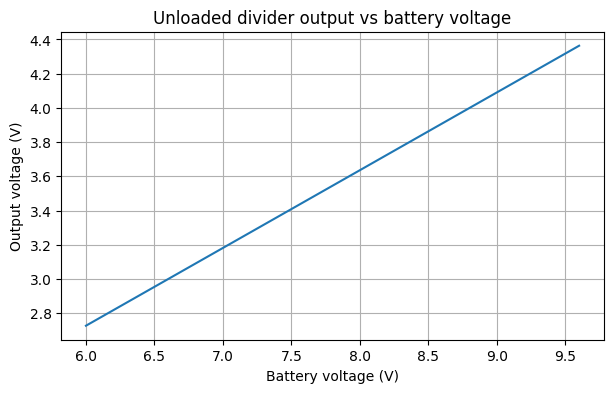

In [2]:
k = R2 / (R1 + R2)
vbat = np.linspace(V_BAT_MIN, V_BAT_MAX, 50)
vout = divider_out(vbat, R1, R2)

print(f"k = {k:.4f}")
print(f"Vout @ {V_BAT_MAX} V = {vout[-1]:.3f} V")
print(f"Vout @ {V_BAT_MIN} V = {vout[0]:.3f} V")

assert np.isclose(k, 0.4545, atol=1e-4)
assert np.isclose(vout[-1], 4.36, atol=0.01)
assert np.isclose(vout[0], 2.73, atol=0.01)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(vbat, vout)
ax.set_xlabel("Battery voltage (V)")
ax.set_ylabel("Output voltage (V)")
ax.set_title("Unloaded divider output vs battery voltage")
fig.savefig(FIG_DIR / "01_vout_vs_vbat.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings.** The output is linear in the battery voltage and spans 2.73 V to 4.36 V. The 4.4 V target is only reached at a fresh battery (9.6 V). Since the output never exceeds 4.36 V, the 5.1 V zener does not conduct in normal operation. It is a protection element, and its only normal-operation effect is leakage (section 8).

## 2. Quiescent current and power
$I_q = \dfrac{V_{bat}}{R_1 + R_2}$, $P_{R1} = I_q^2 R_1$, $P_{R2} = I_q^2 R_2$.
The worst case is at the highest battery voltage. Expected $I_q \approx 44\,\mu$A.

In [3]:
i_q = vbat / (R1 + R2)
p_r1 = i_q**2 * R1
p_r2 = i_q**2 * R2

print(f"Iq @ {V_BAT_MAX} V = {i_q[-1] * 1e6:.1f} uA")
print(f"P(R1) = {p_r1[-1] * 1e3:.3f} mW, P(R2) = {p_r2[-1] * 1e3:.3f} mW")
print(f"Rating margin: {P_RATED / p_r1[-1]:.0f}x (R1), {P_RATED / p_r2[-1]:.0f}x (R2)")

assert np.isclose(i_q[-1] * 1e6, 44, atol=1)

Iq @ 9.6 V = 43.6 uA
P(R1) = 0.228 mW, P(R2) = 0.190 mW
Rating margin: 1094x (R1), 1313x (R2)


**Findings.** Each resistor dissipates about 0.2 mW, more than 1000 times below the 1/4 W rating, so power rating is irrelevant here. The constraints are accuracy and loading. The 44 µA quiescent draw is small, but it is continuous: it drains a typical 9 V battery (a few hundred mAh) over months, not years.

## 3. Thevenin equivalent
Seen from the output, the divider is a source $V_{th} = k \cdot V_{bat}$ in series with
$R_{th} = R_1 \parallel R_2$. Everything that loads, filters or leaks at the output interacts with this one resistance.
Expected $R_{th} = 54.5\,\text{k}\Omega$.

In [4]:
R_th = parallel(R1, R2)
print(f"R_th = {R_th / 1e3:.2f} kOhm")
assert np.isclose(R_th, 54.5e3, rtol=1e-3)

R_th = 54.55 kOhm


**Findings.** $R_{th} = 54.55\,\text{k}\Omega$. This is the output impedance of the circuit, and it explains the next three sections: loading error, filter time constant and leakage error all scale with it.

## 4. Loaded divider
A load $R_L$ sits in parallel with $R_2$. Using the Thevenin equivalent:
$V_{out} = V_{th} \dfrac{R_L}{R_L + R_{th}}$, so the relative error is $\dfrac{R_{th}}{R_L + R_{th}} \approx \dfrac{R_{th}}{R_L}$.
Rule of thumb: for an error below 5 % the load must be at least $19 \cdot R_{th}$.

RL =   1000 kOhm -> Vout = 4.138 V
RL =    100 kOhm -> Vout = 2.824 V
RL =     10 kOhm -> Vout = 0.676 V
5 % error at RL = 1.04 MOhm


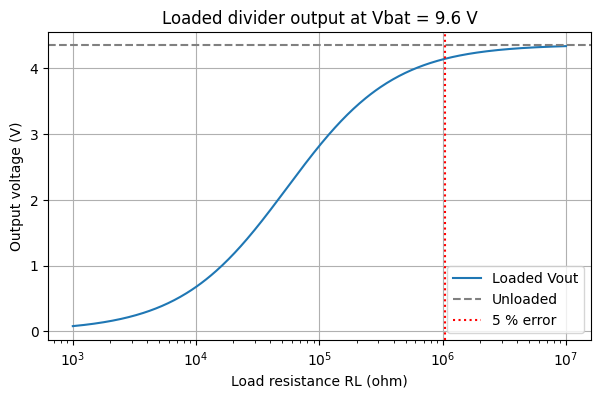

In [5]:
rl = np.logspace(3, 7, 400)   # 1 kOhm to 10 MOhm (extended so the 5 % point is visible)
vout_l = divider_out(V_BAT_MAX, R1, R2, rl)
v_unloaded = divider_out(V_BAT_MAX, R1, R2)
rl_5pct = (1 / 0.05 - 1) * R_th

for rl_chk, expected in [(1e6, 4.14), (100e3, 2.82), (10e3, 0.68)]:
    v = divider_out(V_BAT_MAX, R1, R2, rl_chk)
    print(f"RL = {rl_chk / 1e3:6.0f} kOhm -> Vout = {v:.3f} V")
    assert np.isclose(v, expected, atol=0.01)
print(f"5 % error at RL = {rl_5pct / 1e6:.2f} MOhm")

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(rl, vout_l, label="Loaded Vout")
ax.axhline(v_unloaded, color="gray", linestyle="--", label="Unloaded")
ax.axvline(rl_5pct, color="red", linestyle=":", label="5 % error")
ax.set_xlabel("Load resistance RL (ohm)")
ax.set_ylabel("Output voltage (V)")
ax.set_title(f"Loaded divider output at Vbat = {V_BAT_MAX} V")
ax.legend()
fig.savefig(FIG_DIR / "02_vout_vs_load.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings.** The loading error exceeds 5 % for any load below 1.04 MΩ (= 19 · R_th). At 1 MΩ the output is 4.14 V, at 100 kΩ it is 2.82 V, and at 10 kΩ it collapses to 0.68 V. This divider can only feed a high-impedance input (a voltmeter, an op-amp or ADC input). That is the motivation for the buffer in phase 5.

## 5. RC time constant and cutoff
C1 charges through $R_{th}$: $\tau = R_{th} C_1$, $f_c = \dfrac{1}{2\pi\tau}$.
Unloaded: $\tau = 5.45$ ms, $f_c \approx 29$ Hz.
With a load, the resistance seen by C1 is $R_{th} \parallel R_L$, so the filter gets faster while the DC level drops.

In [6]:
tau = R_th * C1
fc = 1 / (2 * np.pi * tau)
print(f"tau = {tau * 1e3:.2f} ms, fc = {fc:.1f} Hz")
assert np.isclose(tau * 1e3, 5.45, atol=0.01)
assert np.isclose(fc, 29, atol=0.5)

print("\nEffect of load:")
for rl_chk in [np.inf, 1e6, 100e3, 10e3]:
    tau_l = parallel(R_th, rl_chk) * C1
    print(f"RL = {rl_chk:>9.0f} ohm: tau = {tau_l * 1e3:5.2f} ms, fc = {1 / (2 * np.pi * tau_l):6.1f} Hz")

tau = 5.45 ms, fc = 29.2 Hz

Effect of load:
RL =       inf ohm: tau =  5.45 ms, fc =   29.2 Hz
RL =   1000000 ohm: tau =  5.17 ms, fc =   30.8 Hz
RL =    100000 ohm: tau =  3.53 ms, fc =   45.1 Hz
RL =     10000 ohm: tau =  0.85 ms, fc =  188.3 Hz


**Findings.** Unloaded, $\tau = 5.45$ ms and $f_c = 29.2$ Hz. A load changes both the DC level and the corner frequency: at 100 kΩ the cutoff rises to 45 Hz, and at 10 kΩ to 188 Hz, so the filter stops filtering. Time constant and DC accuracy degrade together, because both are set by the same $R_{th}$.

## 6. Worst-case tolerance
The output is highest when R2 is at its upper and R1 at its lower tolerance limit, and lowest in the opposite case.
This bound is guaranteed but pessimistic: both resistors must be at their extremes at once.
Expected at 9.6 V: 4.32 to 4.41 V (1 %) and 4.13 to 4.60 V (5 %).

In [7]:
def worst_case(vbat, tol):
    hi = divider_out(vbat, R1 * (1 - tol), R2 * (1 + tol))
    lo = divider_out(vbat, R1 * (1 + tol), R2 * (1 - tol))
    return lo, hi


wc = {}
for tol, (exp_lo, exp_hi) in [(0.01, (4.32, 4.41)), (0.05, (4.13, 4.60))]:
    lo, hi = worst_case(V_BAT_MAX, tol)
    wc[tol] = (lo, hi)
    print(f"{tol:.0%}: {lo:.3f} to {hi:.3f} V  (span {hi - lo:.3f} V)")
    assert np.isclose(lo, exp_lo, atol=0.01) and np.isclose(hi, exp_hi, atol=0.01)

1%: 4.316 to 4.411 V  (span 0.095 V)
5%: 4.127 to 4.603 V  (span 0.476 V)


**Findings.** With 1 % resistors the output is 4.316 to 4.411 V (about ±47 mV, ±1.1 %). With 5 % resistors it is 4.127 to 4.603 V (about ±238 mV, ±5.5 %). The relative error at the output is about 1.1 times the resistor tolerance, because both resistors contribute and partially add.

## 7. Monte Carlo
10 000 random resistor pairs. The tolerance band only gives limits, not the distribution, so two assumptions are compared:
- uniform within ± tol (pessimistic: any value in the band is equally likely)
- normal with sigma = tol/3 (limits are 3 sigma)

Question: how close do the sampled extremes get to the worst-case bounds from section 6?

1% uniform : mean 4.364  std  19.5 mV  min 4.317  max 4.411
1% normal  : mean 4.363  std  11.3 mV  min 4.316  max 4.405


5% uniform : mean 4.364  std  96.4 mV  min 4.132  max 4.601
5% normal  : mean 4.363  std  56.3 mV  min 4.148  max 4.577


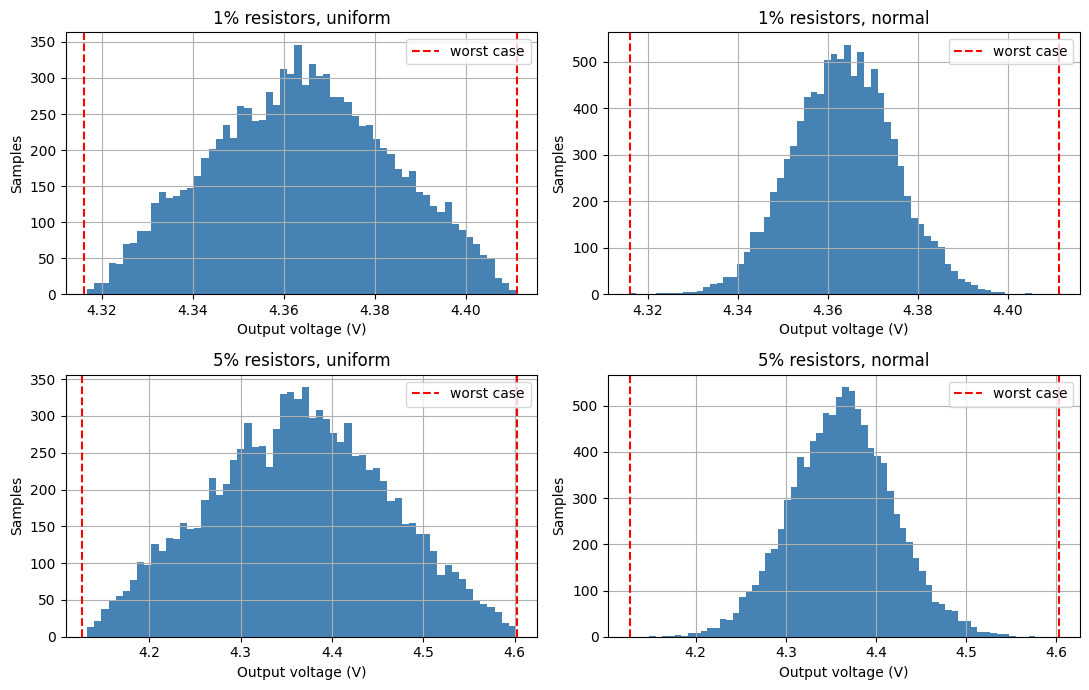

In [8]:
rng = np.random.default_rng(42)   # fixed seed -> reproducible; keep it in this cell
N = 10_000


def monte_carlo(tol, dist, vbat=V_BAT_MAX):
    if dist == "uniform":
        r1 = R1 * (1 + rng.uniform(-tol, tol, N))
        r2 = R2 * (1 + rng.uniform(-tol, tol, N))
    else:  # normal, sigma = tol / 3
        r1 = R1 * (1 + rng.normal(0, tol / 3, N))
        r2 = R2 * (1 + rng.normal(0, tol / 3, N))
    return divider_out(vbat, r1, r2)


fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, tol in enumerate([0.01, 0.05]):
    for col, dist in enumerate(["uniform", "normal"]):
        v = monte_carlo(tol, dist)
        ax = axes[row, col]
        ax.hist(v, bins=60, color="steelblue")
        lo, hi = wc[tol]
        ax.axvline(lo, color="red", linestyle="--", label="worst case")
        ax.axvline(hi, color="red", linestyle="--")
        ax.set_title(f"{tol:.0%} resistors, {dist}")
        ax.set_xlabel("Output voltage (V)")
        ax.set_ylabel("Samples")
        ax.legend()
        print(f"{tol:.0%} {dist:8s}: mean {v.mean():.3f}  std {v.std() * 1e3:5.1f} mV  "
              f"min {v.min():.3f}  max {v.max():.3f}")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_monte_carlo.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings.** The mean is 4.364 V in all four cases, equal to the nominal value, so the tolerances cause scatter but no systematic offset.

| Case | σ | Sample range | Worst case |
|---|---|---|---|
| 1 %, uniform | 19.5 mV | 4.317 to 4.411 V | 4.316 to 4.411 V |
| 1 %, normal | 11.3 mV | 4.316 to 4.405 V | 4.316 to 4.411 V |
| 5 %, uniform | 96.4 mV | 4.132 to 4.601 V | 4.127 to 4.603 V |
| 5 %, normal | 56.3 mV | 4.148 to 4.577 V | 4.127 to 4.603 V |

With a uniform distribution, 10 000 samples reach within a few mV of the worst-case corners, so the bound is tight when every value in the band is equally likely. With a normal distribution, 3σ is about ±34 mV for 1 % resistors, against ±47.6 mV for worst case, so the bound is about 1.4 times more pessimistic than a typical batch. Real resistors from a production line are closer to the normal case, which means the worst case is a safe but conservative design limit.

## 8. Zener leakage error
Below its breakdown voltage the zener still leaks a small current $I_R$, which acts as an extra load drawn from the output node.
That current flows through $R_{th}$, so the error is $\Delta V = I_R \cdot R_{th}$ (the output is pulled down).

Datasheet (Vishay BZX55-series, BZX55C5V1): $I_R < 0.1\,\mu$A at $T_{amb} = 25\,°$C and $< 2\,\mu$A at $150\,°$C, both measured at $V_R = 1$ V. $V_Z$ is 4.8 / 5.1 / 5.4 V (min / nom / max) at 5 mA.
Caveat: the datasheet gives $I_R$ at 1 V, far below 4.4 V, and leakage rises toward the knee, so the 25 °C figure is a lower-bound estimate. The LTspice model in phase 2 will show the behaviour near 4.4 V.

In [9]:
I_R_DATASHEET = 0.1e-6   # ampere, max at 25 C, measured at VR = 1 V (Vishay BZX55-series)

v_nom = divider_out(V_BAT_MAX, R1, R2)
half_span_1pct = (wc[0.01][1] - wc[0.01][0]) / 2

print(f"Datasheet value: dV = {I_R_DATASHEET * R_th * 1e3:.1f} mV "
      f"({I_R_DATASHEET * R_th / v_nom:.2%} of {v_nom:.2f} V)")
print(f"1 % resistor tolerance (half span): {half_span_1pct * 1e3:.1f} mV\n")

print("Sensitivity to the leakage current:")
for i_r in [100e-9, 500e-9, 1e-6, 2e-6, 5e-6]:
    dv = i_r * R_th
    print(f"I_R = {i_r * 1e6:4.1f} uA -> dV = {dv * 1e3:6.1f} mV ({dv / v_nom:.2%})")

print("\nDatasheet limits:")
for label, i_r in [("25 C, datasheet max @ 1 V", 0.1e-6),
                   ("150 C, datasheet max @ 1 V", 2e-6)]:
    dv = i_r * R_th
    print(f"{label:28s}: dV = {dv * 1e3:6.1f} mV ({dv / v_nom:.2%})")
print(f"1 % resistor tolerance: +/- {half_span_1pct * 1e3:.1f} mV")

margin = 4.8 - wc[0.05][1]
print(f"\nMargin between 5 % worst-case high ({wc[0.05][1]:.3f} V) and Vz min (4.8 V): {margin * 1e3:.0f} mV")

Datasheet value: dV = 5.5 mV (0.12% of 4.36 V)
1 % resistor tolerance (half span): 47.6 mV

Sensitivity to the leakage current:
I_R =  0.1 uA -> dV =    5.5 mV (0.12%)
I_R =  0.5 uA -> dV =   27.3 mV (0.62%)
I_R =  1.0 uA -> dV =   54.5 mV (1.25%)
I_R =  2.0 uA -> dV =  109.1 mV (2.50%)
I_R =  5.0 uA -> dV =  272.7 mV (6.25%)

Datasheet limits:
25 C, datasheet max @ 1 V   : dV =    5.5 mV (0.12%)
150 C, datasheet max @ 1 V  : dV =  109.1 mV (2.50%)
1 % resistor tolerance: +/- 47.6 mV

Margin between 5 % worst-case high (4.603 V) and Vz min (4.8 V): 197 mV


**Findings.** At 25 °C the datasheet limit gives $\Delta V \approx 5.5$ mV (0.12 %), negligible next to the ±47.6 mV of 1 % resistors. At 150 °C the limit is 2 µA, which gives 109 mV (2.5 %) and exceeds the resistor tolerance, so leakage is strongly temperature dependent.

The 25 °C number is only a lower bound. It is specified at 1 V, and at 4.4 V the zener is much closer to its knee (V_Z min is 4.8 V), where leakage grows rapidly. The sensitivity table shows that already 1 µA at 4.4 V would cost 54 mV, comparable to the whole 1 % tolerance band. For 5 % resistors the output can reach 4.60 V, only about 0.2 V below V_Z min, where the approximation $\Delta V = I_R R_{th}$ with a constant $I_R$ is no longer valid. The real value at 4.4 V is not in the datasheet, so the LTspice zener model (phase 2) must be used to check it, and the difference to this section will be an expected finding, not an error.

## 9. Results summary
Key numbers collected in one place, checked against the reference values from the project brief. These are compared with LTspice in phase 2.

In [10]:
summary = [
    ("Divider ratio", k, 0.4545),
    (f"Vout @ {V_BAT_MAX} V (V)", divider_out(V_BAT_MAX, R1, R2), 4.36),
    (f"Vout @ {V_BAT_MIN} V (V)", divider_out(V_BAT_MIN, R1, R2), 2.73),
    ("Quiescent current (uA)", V_BAT_MAX / (R1 + R2) * 1e6, 44),
    ("Thevenin resistance (kOhm)", R_th / 1e3, 54.5),
    ("Time constant (ms)", tau * 1e3, 5.45),
    ("Cutoff frequency (Hz)", fc, 29),
    ("Worst case 1 %, low (V)", wc[0.01][0], 4.32),
    ("Worst case 1 %, high (V)", wc[0.01][1], 4.41),
    ("Worst case 5 %, low (V)", wc[0.05][0], 4.13),
    ("Worst case 5 %, high (V)", wc[0.05][1], 4.60),
    ("Vout, RL = 1 MOhm (V)", divider_out(V_BAT_MAX, R1, R2, 1e6), 4.14),
    ("Vout, RL = 100 kOhm (V)", divider_out(V_BAT_MAX, R1, R2, 100e3), 2.82),
    ("Vout, RL = 10 kOhm (V)", divider_out(V_BAT_MAX, R1, R2, 10e3), 0.68),
]

print(f"{'Quantity':30s} {'Computed':>10s} {'Expected':>10s} {'Diff':>8s}")
max_diff = 0
for name, val, exp in summary:
    diff = 100 * (val - exp) / exp
    max_diff = max(max_diff, abs(diff))
    print(f"{name:30s} {val:10.4g} {exp:10.4g} {diff:7.2f}%")

assert max_diff < 1.0, f"largest deviation {max_diff:.2f} % exceeds 1 %"
print(f"\nLargest deviation from the reference values: {max_diff:.2f} %")

Quantity                         Computed   Expected     Diff
Divider ratio                      0.4545     0.4545    0.01%
Vout @ 9.6 V (V)                    4.364       4.36    0.08%
Vout @ 6.0 V (V)                    2.727       2.73   -0.10%
Quiescent current (uA)              43.64         44   -0.83%
Thevenin resistance (kOhm)          54.55       54.5    0.08%
Time constant (ms)                  5.455       5.45    0.08%
Cutoff frequency (Hz)               29.18         29    0.62%
Worst case 1 %, low (V)             4.316       4.32   -0.09%
Worst case 1 %, high (V)            4.411       4.41    0.03%
Worst case 5 %, low (V)             4.127       4.13   -0.08%
Worst case 5 %, high (V)            4.603        4.6    0.06%
Vout, RL = 1 MOhm (V)               4.138       4.14   -0.05%
Vout, RL = 100 kOhm (V)             2.824       2.82    0.13%
Vout, RL = 10 kOhm (V)             0.6761       0.68   -0.58%

Largest deviation from the reference values: 0.83 %


**Findings.** All 14 values agree with the reference table within 1 % (the differences come from the rounding of the reference values). The calculation model is consistent, so any larger deviation in phase 2 can be attributed to LTspice effects (the zener model, in particular) and not to errors here.